# Pandas Assessment Lab: reading online discussions

Welcome! This is a **1-hour, open-book, ungraded** check-up. Its only purpose is to show **you** (and us) what already feels solid and what needs a bit more practice. Use your slides, the pandas docs, or a neighbour. Nobody sees a grade.

We work with **SynDisco**, a dataset of 720 *synthetic* online discussions in which seven simulated users debate a topic and an LLM moderator may (or may not) step in. The data comes to you **already cleaned**, so we can spend the hour on thinking with pandas. Everything is based on the intro-to-pandas slides; where you need a small extra (a parameter, a method), the task says *hint* and you may look it up.

| Minutes | Block | What you do |
|---|---|---|
| 0-15 | 1. Get to know the data | read a short tour, answer 5 quick questions |
| 15-30 | 2. Quiz | 7 "what does this return?" questions and 3 short code reads |
| 30-50 | 3. Build the query | 5 queries, about 4 minutes each (2½ to build, 1½ to discuss), plus an extra Task 6 if time allows, from "fill one gap" to "write the plan yourself" |
| 50-60 | 4. Broken queries | fix 3 snippets that crash, lie, or surprise |

**How the checks work.** Almost every task is followed by a small `assert` cell. If it prints `✓`, you are right. If you get an `AssertionError`, read the hint in the message, change your answer and run the check again. A cell with `...` is a **gap** for you to fill.

**Tips.** Run the cells from top to bottom. Every cell is safe to re-run. Work on copies (`df = msgs.copy()`) if you want to change a table. Only `pandas` and `numpy` are needed.

---
## Block 1: Get to know the data

Run the next cell. It downloads the data (once), loads it, and applies some cleaning steps. You do not need to understand every line of this cell; the comments tell you what was done.

In [1]:
import json
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd

# --- 1) download and unzip the SynDisco data (skipped if it is already here)
URL = "https://github.com/dimits-ts/syndisco/raw/master/viewer_datasets/online.zip"
if not Path("online").exists():
    if not Path("online.zip").exists():
        urllib.request.urlretrieve(URL, "online.zip")
    with zipfile.ZipFile("online.zip") as z:
        z.extractall()

# --- 2) load: one dict per conversation file, folder name kept as `experiment`
rows = []
for folder in sorted(Path("online").iterdir()):
    for file in sorted(folder.glob("*.json")):
        with open(file) as f:
            d = json.load(f)
        d["experiment"] = folder.name
        rows.append(d)
raw = pd.DataFrame(rows)

# --- 3) table `convs`: one row per conversation
parts = raw["experiment"].str.split("_", n=1)           # "qwen7b_vanilla.txt" -> ["qwen7b", "vanilla.txt"]
convs = pd.DataFrame({
    "conv_id": raw["id"],                                                     # renamed from `id`
    "started_at": pd.to_datetime(raw["timestamp"], format="%y-%m-%d-%H-%M"),  # text -> datetime
    "experiment": raw["experiment"],
    "model": parts.str[0],
    "setting": parts.str[1].str.replace(".txt", "", regex=False),
    "has_moderator": raw["moderator"].notna().astype(int),                    # NaN / "moderator" -> 0 / 1
    "n_messages": raw["logs"].str.len(),                                      # messages in the file
})

# --- 4) table `msgs`: one row per message (the nested `logs` lists, exploded)
msgs = raw[["id", "logs"]].explode("logs", ignore_index=True)
msgs["turn"] = msgs.groupby("id").cumcount() + 1                              # 1st, 2nd, 3rd... message
msgs["speaker"] = msgs["logs"].str["name"]
msgs["written_by"] = msgs["logs"].str["model"].replace("hardcoded", "real comment")
msgs["text"] = msgs["logs"].str["text"]
msgs = msgs.drop(columns="logs").rename(columns={"id": "conv_id"})
msgs = msgs[msgs["text"] != '""'].reset_index(drop=True)                      # silent turns dropped

# --- 5) derived columns
msgs["is_mod"] = msgs["speaker"] == "moderator"
msgs["n_chars"] = msgs["text"].str.len()
msgs["n_words"] = msgs["text"].str.split().str.len()
first = msgs["text"].str.extract(r"@([\w-]+)")[0]                             # first @name in the text
msgs["addressed_to"] = pd.Series(np.where(first == "moderator", "moderator", "user"),
                                 index=msgs.index).where(first.notna())       # no @name -> NaN

print("convs:", convs.shape, "| msgs:", msgs.shape)

convs: (720, 7) | msgs: (18658, 9)


#### How `explode` made `msgs`

The raw file has **one row per conversation**, and the column `logs` holds a whole *list* of messages in each cell. `explode("logs")` gives every message its own row and repeats the `id` (renamed `conv_id` later). Each message is still a dict, so `.str["name"]`, `.str["text"]` and `.str["model"]` pick one key each into a column of its own.

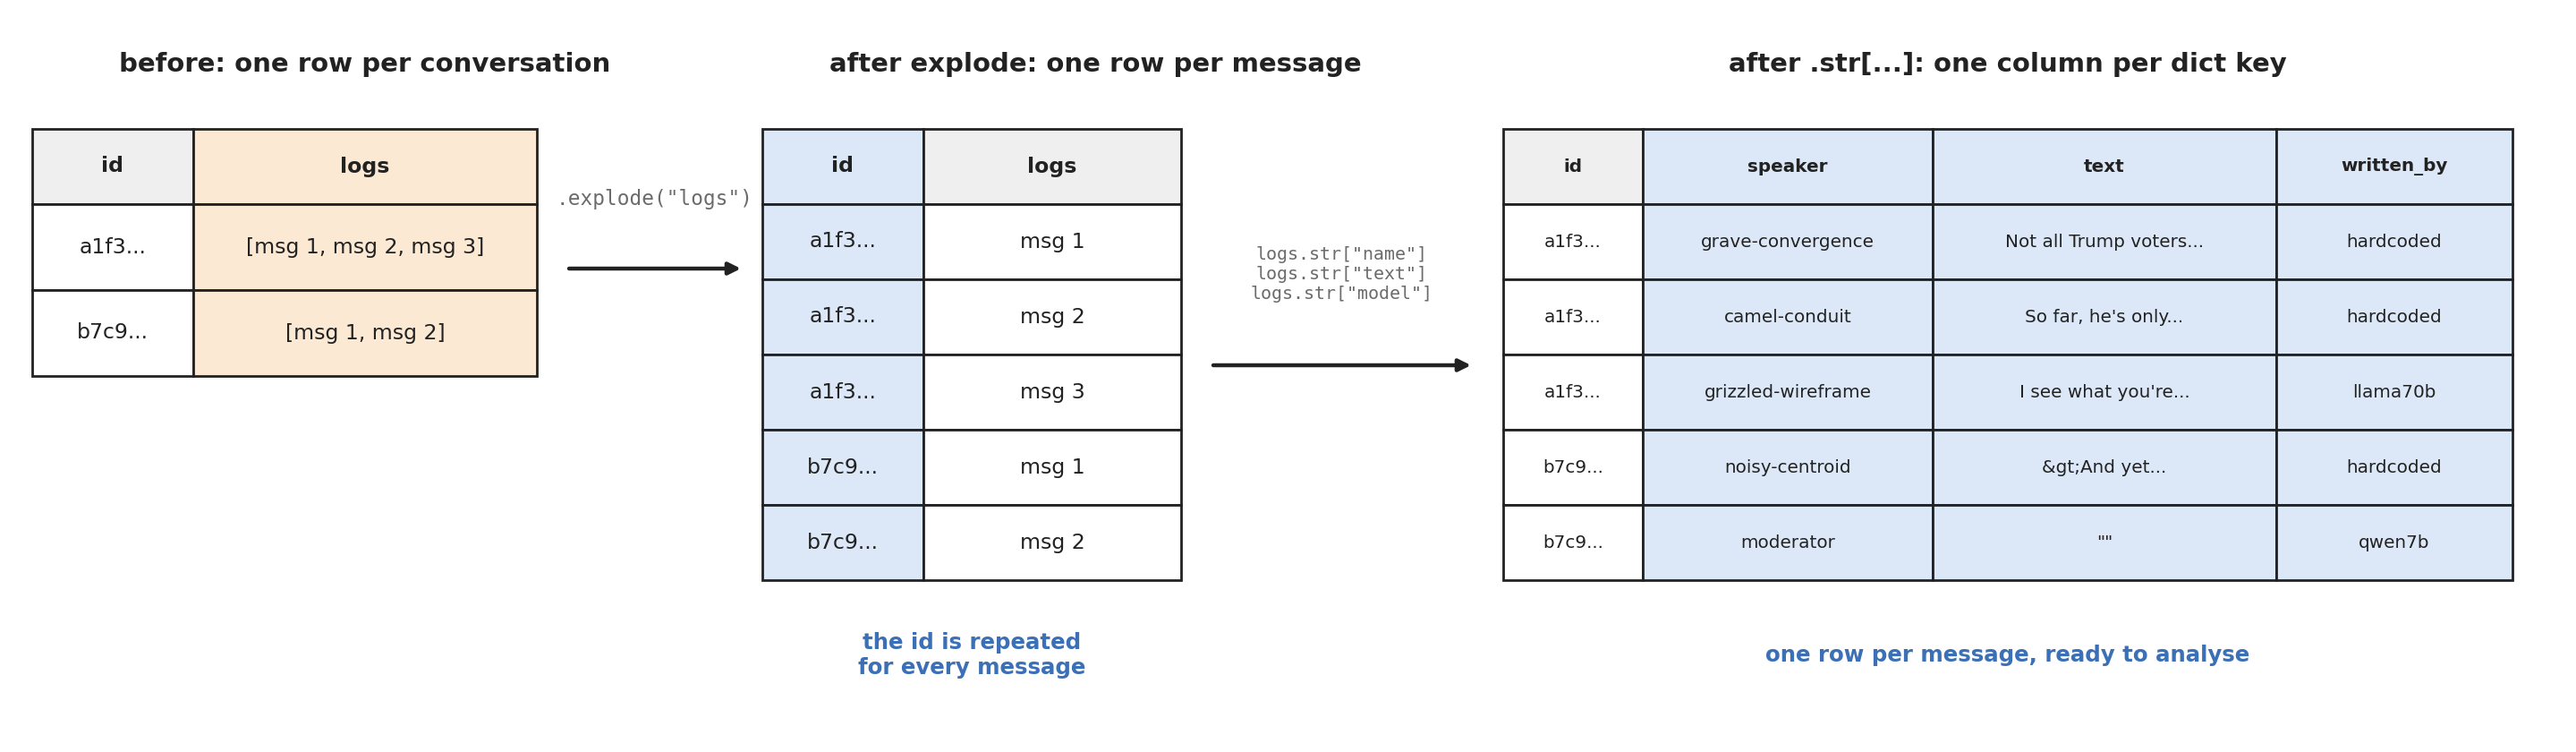

In [39]:
# helper for the checks below: it compares your answer with a fingerprint of the right one.
# You do not need to read it. (A wrong answer fails the assert, a right one passes.)
import hashlib

def _norm(v):
    if isinstance(v, dict):
        return [[k, _norm(x)] for k, x in sorted(v.items())]
    if hasattr(v, "tolist"):
        v = v.tolist()
    if isinstance(v, (list, tuple)):
        return [_norm(x) for x in v]
    if isinstance(v, float):
        v = round(v, 1)
        return int(v) if v == int(v) else v
    return v

def ok(value, key):
    return hashlib.sha1(repr(_norm(value)).encode()).hexdigest()[:8] == key

### The tour: what was already cleaned

Compared with the raw JSON files (one nested file per conversation), the two tables you have now (`convs` and `msgs`) went through these steps:

| Step | What happened |
|---|---|
| **Renamed** | `id` became `conv_id`, so the same key has the same name in both tables. |
| **Dates parsed** | the text `timestamp` (like `26-02-09-19-01`) became the real datetime `started_at`. |
| **Split** | the folder name `experiment` (like `qwen7b_vanilla.txt`) was cut into `model` and `setting`. |
| **Missing turned into a flag** | the raw `moderator` column was `NaN` when there was no moderator; it became `has_moderator` (0/1). |
| **Dropped columns** | `ctx_length` (always 3), `users` and `logs` (nested lists; `logs` was exploded into `msgs`). |
| **Dropped rows** | the 1,682 messages that were just `""` (the moderator is allowed to stay silent). |
| **Recoded** | `written_by == "hardcoded"` became `"real comment"`: the opening comments are real, not written by a model. |
| **Derived columns** | `turn`, `is_mod`, `n_chars`, `n_words`, `addressed_to` ("moderator", "user", or `NaN` if the message has no `@name`), `n_messages`. |

`convs` has **one row per conversation**, `msgs` has **one row per message**, and `conv_id` links them. Have a look:

In [40]:
convs.head(3)

,conv_id,started_at,experiment,model,setting,has_moderator,n_messages
0,1327e2a5-f931-4212-a1d9-b3efb7fb5348,2026-02-09 19:01:00,llama70b_constructive_communications.txt,llama70b,constructive_communications,1,32
1,b3805d66-7317-44c0-99d8-d724b85d97ed,2026-02-09 19:19:00,llama70b_constructive_communications.txt,llama70b,constructive_communications,1,32
2,70da56c7-4b0d-4b19-823f-1b6914dc6ffa,2026-02-09 19:34:00,llama70b_constructive_communications.txt,llama70b,constructive_communications,1,32


In [41]:
msgs.drop(columns="text").head(3)

,conv_id,turn,speaker,written_by,is_mod,n_chars,n_words,addressed_to
0,1327e2a5-f931-4212-a1d9-b3efb7fb5348,1,grave-convergence,real comment,False,500,88,NaN
1,1327e2a5-f931-4212-a1d9-b3efb7fb5348,2,camel-conduit,real comment,False,349,63,NaN
2,1327e2a5-f931-4212-a1d9-b3efb7fb5348,3,grizzled-wireframe,llama70b,False,402,73,user


In [42]:
convs.info()
print()
msgs.info()

<class 'pandas.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   conv_id        720 non-null    str           
 1   started_at     720 non-null    datetime64[us]
 2   experiment     720 non-null    str           
 3   model          720 non-null    object        
 4   setting        720 non-null    object        
 5   has_moderator  720 non-null    int64         
 6   n_messages     720 non-null    int64         
dtypes: datetime64[us](1), int64(2), object(2), str(2)
memory usage: 81.9+ KB

<class 'pandas.DataFrame'>
RangeIndex: 18658 entries, 0 to 18657
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   conv_id       18658 non-null  str   
 1   turn          18658 non-null  int64 
 2   speaker       18658 non-null  object
 3   written_by    18658 non-null  object
 4   text          1

### Five quick questions

Just get a feel for the data: no complex queries yet. Answer in the cell under each question, then run the check cell below it. Finding the right pandas method is part of the task (open book: use the slides).

**Q1 · Size.** How many rows and columns does each table have? Give each as a tuple `(rows, columns)`.

In [45]:
convs_shape = convs.shape
msgs_shape = msgs.shape

In [ ]:
assert ok(convs_shape, "ed1a7ce6"), "convs: count rows and columns with .shape"
assert ok(msgs_shape, "778d2b89"), "msgs: count rows and columns with .shape"
print("✓ Q1")

**Q2 · Summary statistics.** Get the summary of the number columns `turn`, `n_chars` and `n_words` of `msgs` (count, mean, std, min, quartiles, max, all in one table). From it, read the **median** and the **max** number of words (`n_words`) of a message.

In [50]:
# your code here
stats=msgs[["turn","n_chars","n_words"]].describe()
median_words = stats.loc["50%","n_words"]
max_words = ...
stats=...

In [ ]:
assert ok(median_words, "a9334987"), "The median is the 50% row of n_words"
assert ok(max_words, "77ba9cd9"), "The max is the last row of n_words"
print("✓ Q2")

**Q3 · Counting categories.** How many conversations does each moderation `setting` have? (Count how often each value appears in a column.) Keep the result in `setting_counts`.

In [53]:
# your code here
setting_counts = convs["setting"].value_counts()
setting_counts

setting
constructive_communications    180
erulemaking                    180
nomod                          180
vanilla                        180
Name: count, dtype: int64

In [ ]:
assert ok(setting_counts.to_dict(), "fe5d740b"), "Count the conversations per setting: which column of convs holds the setting?"
print("✓ Q3")

**Q4 · Missing values.** Which column of `msgs` has missing values, and how many? (Count the missing values of every column.)

In [ ]:
missing = msgs.isna().sum() # Find sum of the missing
missing = ...          # keep only the columns that have missing values
missing_col = ...  # keep index/name of the missing column
n_missing =... # keep the value
missing

In [54]:
missing = msgs.isna().sum() 
missing

conv_id            0
turn               0
speaker            0
written_by         0
text               0
is_mod             0
n_chars            0
n_words            0
addressed_to    3459
dtype: int64

In [ ]:
assert ok(missing_col, "060fdf68"), "Which column has a count above 0?"
assert ok(n_missing, "6147f9fb"), "Read the count of that column"
print("✓ Q4: those NaN are not errors, they mean the message has no @name")

**Q5 · Dates.** `started_at` is a real datetime. When did the first and the last conversation start?

In [58]:
# your code here
first_start = convs["started_at"].median()
last_start = ...
print(first_start, "->", last_start)

2026-02-11 11:41:30 -> Ellipsis


In [ ]:
assert ok(str(first_start)[:10], "11390544"), "The first start is the smallest datetime"
assert ok(str(last_start)[:10], "9a3c9ee3"), "The last start is the largest datetime"
print("✓ Q5")

---
## Block 2: Quiz

**10 questions.** Predict first, run second! For each question, **decide your answer before running anything**. Then put the letter in the `answers` cell and run the check at the end of the block. You may run the code afterwards, to see why you were right or wrong.

Small tables for the concept questions:

In [ ]:
toy = pd.DataFrame(
    {"team": ["a", "a", "b", "b", "c"], "score": [10, np.nan, 7, 3, np.nan]},
    index=[10, 11, 12, 13, 14],
)
left = pd.DataFrame({"k": [1, 2, 2, 3], "x": list("abcd")})
right = pd.DataFrame({"k": [2, 3, 3, 4], "y": list("wxyz")})
toy

The same three tables as a picture, so you can think on it. In `toy` the grey column is the **index** (the *labels*), and the small grey words are the *positions*. In `left` and `right`, rows with the same colour have the same key `k`.

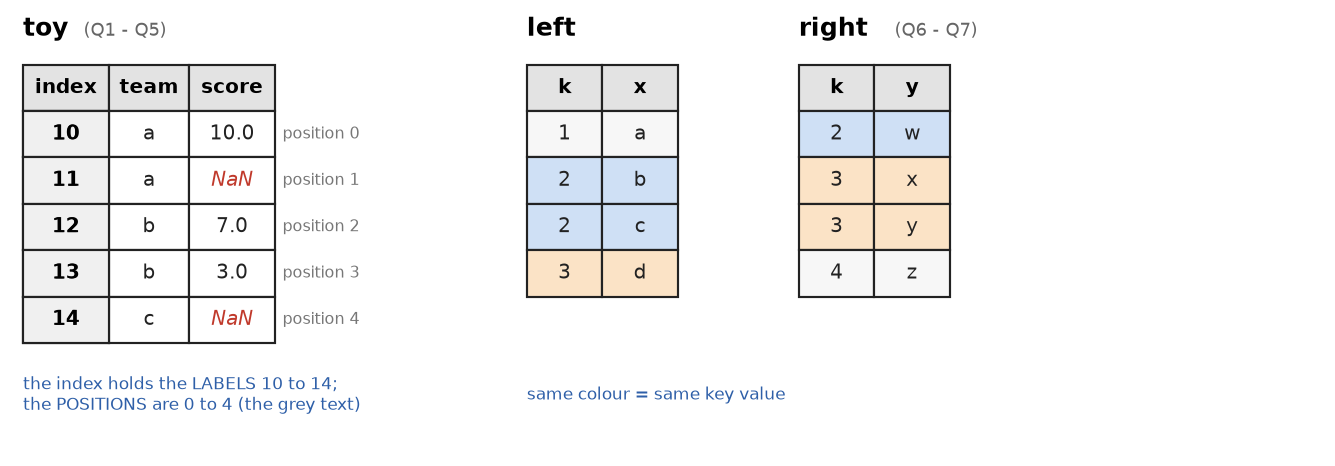

### Part A · What does this return?

**Q1.** `len(toy.loc[11:13])`
A) KeyError  B) 2  C) 4  D) 3

**Q2.** `((toy["score"] > 5) & (toy["team"] == "a")).sum()`
A) 1  B) 2  C) 3  D) 4

**Q3.** `toy["score"] > 5 & toy["team"] == "a"`  (no parentheses)
A) a ValueError ("truth value is ambiguous")  B) a TypeError  C) the same as Q2  D) a Series with two `True`

**Q4.** `toy["score"].mean()`
A) 4.0  B) 20.0  C) 6.67  D) NaN

**Q5.** `toy.groupby("team")["score"].agg(["mean", "count"]).shape`
A) (5, 2)  B) (3, 3)  C) (2, 3)  D) (3, 2)

**Q6.** `len(left.merge(right, on="k"))`  (the default merge)
A) 4  B) 2  C) 3  D) 6

**Q7.** `len(left.merge(right, on="k", how="left"))`
A) 4  B) 6  C) 5  D) 7

### Part B · What does this compute?

Say it in plain words (one short sentence in `words`) and pick the best description. The snippets use `msgs`.

**R1.** `msgs.loc[msgs["is_mod"], "n_words"].median()`
A) the median words of all messages  B) the median words of the moderator's messages  C) the median words per conversation  D) the number of moderator messages

**R2.** `msgs.groupby(["written_by", "is_mod"])["n_words"].agg(["mean", "std"])`
A) the number of messages per writer  B) the mean words of the moderator only  C) the mean and std of words of all messages  D) one row per writer and role, with the mean and the std of the words

**R3.** `msgs["addressed_to"].isna().groupby(msgs["written_by"]).mean()`
A) for each writer, the share of messages that mention nobody  B) how many messages with an @name each writer has  C) the share of all messages written by each writer  D) the number of NaN in the whole column

Fill in your answers: one letter per question (`"?"` means not answered yet), and a sentence in your own words for R1-R3.

In [ ]:
answers = {
    "q1": "?", "q2": "?", "q3": "?", "q4": "?", "q5": "?", "q6": "?", "q7": "?",
    "r1": "?", "r2": "?", "r3": "?",
}
words = {
    "r1": "...", "r2": "...", "r3": "...",
}


In [ ]:
import hashlib

def _h(q, a):
    return hashlib.sha1((q + str(a).strip().lower()).encode()).hexdigest()[:8]

_key = {"q1": "d76e52c0", "q2": "9c29c71c", "q3": "9bbfcd43", "q4": "ee00c13c", "q5": "936f6fa0", "q6": "75771f80", "q7": "12d167b1", "r1": "96409a35", "r2": "5c60a29d", "r3": "4742cd7c"}

wrong = [q for q in _key if _h(q, answers.get(q, "?")) != _key[q]]
for q in _key:
    print(q, "✓" if q not in wrong else "✗ look again")

assert all("..." not in w and len(w.strip()) > 10 for w in words.values()), "Write your plain-words sentence for R1-R3 in `words`"
assert not wrong, f"Not yet right: {wrong}. Run the snippet on the toy tables, it is allowed!"
print("\n✓ Quiz done")

---
## Block 3: Build the query

**5 queries, about 4 minutes each** (roughly 2½ minutes to build and 1½ to talk about it together), plus a short **Task 6** if time allows. If you are faster, use the spare time to check your answer in a second way.

Before writing any pandas, **write the recipe as comments**. Every query can be answered with the same five questions:

1. **Which rows?** (a filter, or all of them)
2. **Which groups?** (none, one column, two columns)
3. **Which statistic?** (count, mean, median, a share...)
4. **Is a join needed?** (does a column live in another table?)
5. **Sort or limit?** (biggest first, top 3...)

Tasks 1-4 come with the recipe filled in and a skeleton with gaps (`...`). In Task 5 **you** write the plan before any code.

### Task 1 · Filter and count
*How many messages written by **users** (not the moderator) have **more than 100 words**?* Fill the gaps.

In [59]:
# 1) which rows:      user messages (not the moderator) with more than 100 words
# 2) which groups:    none
# 3) which statistic: how many rows pass the filter
# 4) join needed:     no
# 5) sort / limit:    no
is_long_user = (~msgs["is_mod"]) & (msgs["n_words"] > 100)
n_long = is_long_user.sum()
n_long

np.int64(1395)

In [60]:
assert ok(n_long, "64bed117"), "Which column holds the number of words? And is the filter on users only?"
print("✓ Task 1")

✓ Task 1


### Task 2 · Group and aggregate
*What is the **mean number of characters** (`n_chars`) of the **user** messages, for each writer (`written_by`)? Show the longest writer first.* Fill the column and the method.

In [61]:
# 1) which rows:      user messages only
# 2) which groups:    one group per writer
# 3) which statistic: the mean of n_chars
# 4) join needed:     no
# 5) sort / limit:    longest first
user_msgs = msgs[~msgs["is_mod"]]
chars_by_writer = user_msgs.groupby("written_by")["n_chars"].mean().sort_values(ascending=False).round(1)
chars_by_writer

written_by
llama8b         619.0
mistral7b       419.5
llama70b        418.6
mistral24b      384.8
qwen7b          355.1
real comment    347.2
qwen32b         251.8
Name: n_chars, dtype: float64

In [62]:
assert ok(len(chars_by_writer), "902ba3cd"), "One value per writer: the 6 models and the real comments"
assert ok([chars_by_writer.index[0], chars_by_writer.iloc[0]], "7f9d7d03"), "Longest first, and the statistic is the mean"
assert ok([chars_by_writer.index[-1], chars_by_writer.iloc[-1]], "6eba8ba8"), "Check the other end of the list too"
print("✓ Task 2")

✓ Task 2


### Task 3 · Filter, group, count, then sort and limit
*Among the user messages with more than 100 words (as in Task 1), which **3 conversations** (`conv_id`) have the most of them? Show how many.* Fill the group column and the method that keeps the first rows.

In [63]:
# 1) which rows:      user messages with more than 100 words
# 2) which groups:    one group per conversation
# 3) which statistic: how many rows in each group
# 4) join needed:     no
# 5) sort / limit:    biggest first, keep 3
long_user = msgs[(~msgs["is_mod"]) & (msgs["n_words"] > 100)]
top3 = long_user.groupby("conv_id").size().sort_values(ascending=False).head(3)
top3

conv_id
b9c54e2b-4d16-4587-80cb-e70e8c8a2897    14
bcf40fd1-825c-4af0-b1f1-2b2cc7c86e48    13
19d786fe-a17e-43cd-968a-5c276502dcf0    13
dtype: int64

In [64]:
assert len(top3) == 3, "Keep only 3 rows"
assert ok(top3.tolist(), "c603b24f"), "Count the long user messages per conversation, biggest first"
print("✓ Task 3")

✓ Task 3


### Task 4 · Two keys and a percentage inside each group
*For each writer (`written_by`) and role (`is_mod`), what **percentage** of its messages mention nobody (`addressed_to` is missing)?*

A `True/False` column has a neat property: its `mean` is the **share of `True`** (True = 1, False = 0). So: make a True/False column, group by the two keys, take the mean, multiply by 100. Fill the gaps.

In [69]:
# 1) which rows:      all messages
# 2) which groups:    two keys: the writer and the role
# 3) which statistic: the share of messages that mention nobody = mean of a True/False column, times 100
# 4) join needed:     no
# 5) sort / limit:    no
df = msgs.copy()
df["no_mention"] = df["addressed_to"].isna()      # True when the message has no @name
share_pct = (df.groupby(["written_by", "is_mod"])["no_mention"].mean() * 100).round(1)
share_pct

written_by    is_mod
llama70b      False       4.0
              True        0.5
llama8b       False       0.4
              True        0.9
mistral24b    False      25.7
              True        0.0
mistral7b     False       5.2
              True       33.6
qwen32b       False      33.8
              True       17.7
qwen7b        False      12.0
              True       11.3
real comment  False     100.0
Name: no_mention, dtype: float64

In [70]:
assert ok(len(share_pct), "bd307a3e"), "One value per (writer, role) pair that exists in the data"
assert ok(share_pct.loc[("qwen32b", False)], "978d4db9"), "Check qwen32b users. Is the statistic a mean of True/False, times 100?"
assert ok(share_pct.loc[("mistral7b", True)], "c3bdda7a"), "Check mistral7b moderator messages"
assert ok(share_pct.loc[("real comment", False)], "310b86e0"), "Check the real comments"
print("✓ Task 4")

✓ Task 4


### Task 5 · Join, then group (you write the plan)
We have a small second table with facts about each model:

In [ ]:
model_info = pd.DataFrame({
    "model": ["llama8b", "llama70b", "mistral7b", "mistral24b", "qwen7b", "qwen32b"],
    "family": ["llama", "llama", "mistral", "mistral", "qwen", "qwen"],
    "billions": [8, 70, 7, 24, 7, 32],
    "size_class": ["small", "large", "small", "medium", "small", "medium"],
})
model_info

*Do bigger models write longer **user** messages? For each `size_class`, count the user messages and compute their mean `n_words`.* The real comments are not written by a model: leave them out.

**Step 1.** Write your plan (replace every `...`). **Step 2.** Write the code. Name the result `words_by_size`: one row per `size_class` and two columns, in this order: the number of messages, the mean words. (*Hint:* the key is called `written_by` in one table and `model` in the other. Rename one of them, or look up `left_on` / `right_on`.)

In [ ]:
plan = """
1) which rows:      ...
2) which groups:    ...
3) which statistic: ...
4) join needed:     ...
5) sort / limit:    ...
"""

In [ ]:
msgs.head()

In [ ]:
# your code here
words_by_size = None

In [ ]:
assert "..." not in plan, "Finish the plan first: replace every ..."
assert words_by_size is not None, "Write the code that creates words_by_size"
assert ok(words_by_size.shape, "a9a52dd0"), "One row per size_class, two columns (count, mean)"
assert ok(words_by_size.iloc[:, 0].sum(), "7d895eb8"), "Total messages: did you leave out the real comments, and only the users?"
assert ok(words_by_size.loc["small"].round(1).tolist(), "67c7ef36"), "Check the small row: [number of messages, mean words]"
assert ok(words_by_size.loc["large"].round(1).tolist(), "fc369cd3"), "Check the large row"
print("✓ Task 5")

### Task 6 · A string method, then filter (if time allows)
***Speaker** names are two words joined by a dash, like `grizzled-wireframe`. How many **user** messages were written by a speaker whose name has **more than 15 characters**?*. Fill the gaps.

In [73]:
# 1) which rows:      user messages whose speaker name is longer than 15 characters
# 2) which groups:    none
# 3) which statistic: how many rows pass the filter
# 4) join needed:     no
# 5) sort / limit:    no
name_len = msgs["speaker"].str.len()          # the length of every speaker name
n_long_names = ((~msgs["is_mod"]) & (name_len > 15)).sum()
n_long_names

np.int64(2922)

In [74]:
assert ok(n_long_names, "b91b385f"), "Which column holds the name, and which string method counts characters? Only user messages count"
print("✓ Task 6")

✓ Task 6


---
## Block 4: Broken queries

Three queries went wrong, each in a different way: one **crashes**, one gives a **silently wrong answer**, one **surprises** you. For each: run the broken cell, write the fix in the cell below it, and check it. We will talk about why each one went wrong together.

### Broken 1 · The crash
*We want the user messages with more than 50 words.*

In [ ]:
# BROKEN: run me
try:
    long_user = msgs[~msgs["is_mod"] and msgs["n_words"] > 50]
    print(len(long_user), "messages")
except ValueError as e:
    print("ValueError:", e)

In [ ]:
# your fix
fixed_1 = None

In [ ]:
assert fixed_1 is not None, "Write the fixed line"
assert ok(len(fixed_1), "c6f73c62"), "The filter should keep the user messages with more than 50 words"
print("✓ Broken 1")

#### Before Broken 2: what a merge does when a key repeats

A merge looks up **every** matching row. Watch what happens to the **number of rows** when the same key appears twice in the table we look things up in:

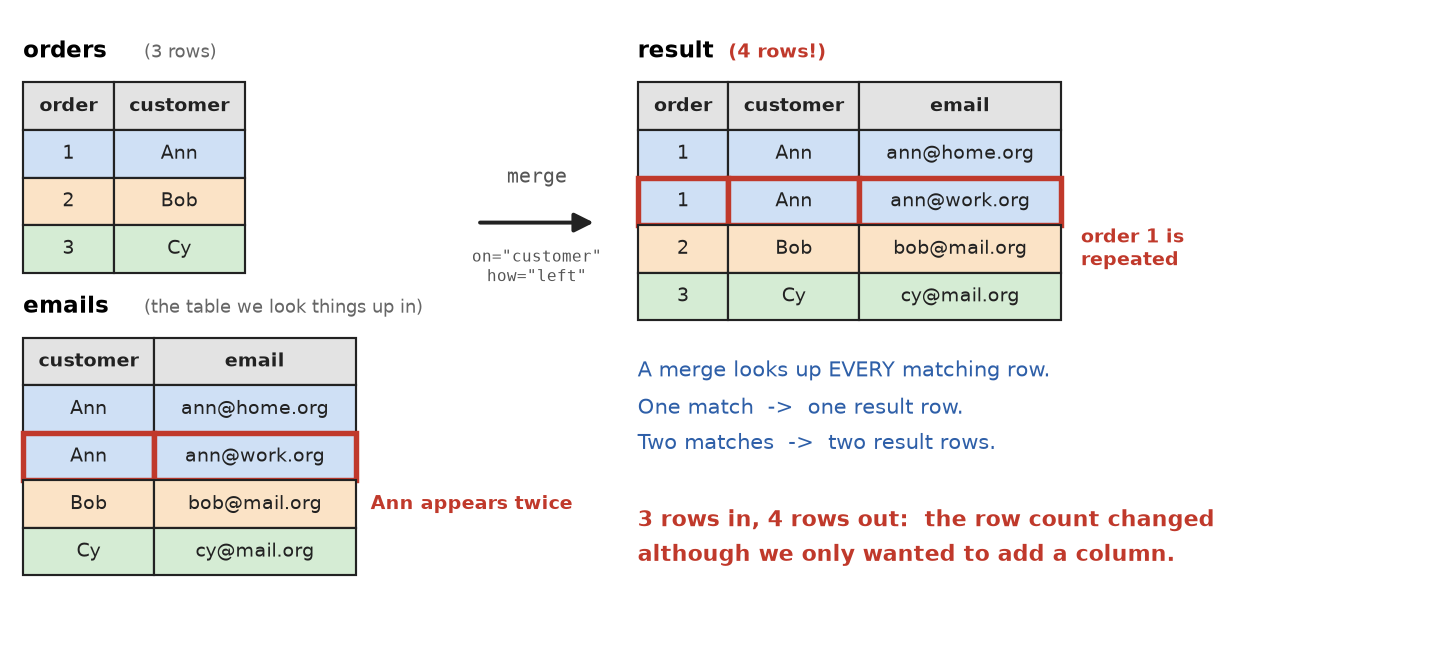

### Broken 2 · The silent wrong answer
*We want to attach the `size_class` of each model to every message, **keeping all messages**, and then count the messages per size class.* The lookup table `sizes` (model -> size class) was collected from two sources.

A left merge that only *adds a column* should leave you with the same number of messages. Run the cell, read the output, and ask yourself: **does it make sense?** Then fix the code so that it does.

In [ ]:
# BROKEN: run me. No error, no warning. Is the answer right?
sizes = pd.DataFrame({
    "model": ["llama8b", "llama70b", "mistral7b", "mistral24b", "qwen7b", "qwen32b", "mistral7b", "qwen7b"],
    "size_class": ["small", "large", "small", "medium", "small", "medium", "small", "small"],
})
print(sizes)

with_size = msgs.merge(sizes, left_on="written_by", right_on="model", how="left")
print("\n", len(msgs), "messages before the merge,", len(with_size), "after")
with_size["size_class"].value_counts()

In [ ]:
# your fix
fixed_2 = None

In [ ]:
assert fixed_2 is not None, "Write the fixed merge"
assert len(fixed_2) == len(msgs), "A left merge with a lookup table must not change the number of messages"
assert ok(fixed_2["size_class"].value_counts().to_dict(), "58b42921"), "Counts per class are still off: check the keys of `sizes`"
print("✓ Broken 2")

### Broken 3 · The surprise
*We want to count the messages for each value of `addressed_to` (to the moderator, to a user, or to nobody). All 18,658 messages should be counted.*

In [ ]:
# BROKEN: run me
by_target = msgs.groupby("addressed_to")["n_words"].size()
print(by_target)
print("\nmessages counted:", by_target.sum(), "of", len(msgs))

In [ ]:
# your fix
fixed_3 = None

In [ ]:
assert fixed_3 is not None, "Write the fixed groupby"
assert fixed_3.sum() == len(msgs), "Every message must be counted. What does groupby do with NaN keys?"
assert ok(len(fixed_3), "77de68da"), "One group per kind of target, including the 'nobody' group"
print("✓ Broken 3")

---
### That's it!

If every cell shows `✓`, you are in good shape. If some did not, you now know which topic to revisit: **filtering and `&`** (Block 2 Q2-Q3, Tasks 1, 3 and 6, Broken 1), **missing values** (Block 1 Q4, Block 2 Q2 and Q4, Broken 3), **groupby** (Block 2 Q5, Tasks 2-4) or **joins** (Block 2 Q6-Q7, Task 5, Broken 2).